# Analyse der Kindersterblichkeit (1990–2024)

## Gruppenmitglieder
Kristjana Nikollaj, Larissa Niklaus, Sara Lissidini

## Forschungsfrage

- Wie hat sich die Sterblichkeitsrate von Kindern unter fünf Jahren in verschiedenen Ländern zwischen 1990 und 2024 entwickelt und in welchen Ländern war sie im Jahr 2024 am höchsten?
- Was sind mögliche Gründe dafür?


## Datenquelle
Our World in Data
https://ourworldindata.org/grapher/child-mortality


## 1. Daten importieren
- Die Kindersterblichkeit ist in **Prozent** angegeben (Anteil der Kinder, die vor dem 5. Geburtstag sterben).

In [2]:
import pandas as pd
from matplotlib import pyplot as plt

In [8]:
df = pd.read_csv('child-mortality.csv', skiprows=1,
                    names=['Gebiet','Code','Jahr','Kindersterblichkeit'])
df.head()

,Gebiet,Code,Jahr,Kindersterblichkeit
0,Afghanistan,AFG,1957,36.82
1,Afghanistan,AFG,1958,36.21
2,Afghanistan,AFG,1959,35.64
3,Afghanistan,AFG,1960,35.06
4,Afghanistan,AFG,1961,34.52


## 2. Daten explorieren

Über die einzelnen Spalten kann Folgendes ausgesagt werden:
- Die Spalte *Gebiet* enthält 213 verschiedene Gebiete. Darunter sind 12 Aggregate (z. B. World, Africa, High-income countries), die keine Länder sind
- Die Spalte *Code* enthält 213 verschiedene Codes (ein Code pro Gebiet)
- Es sind Daten zwischen 1751 und 2024 vorhanden. Ab dem Jahr 1985 sind alle 213 Gebiete vertreten
- Die Kindersterblichkeit streut zwischen 0.13 % und 78.09 %

In [5]:
df.dtypes

Entity                                      str
Code                                        str
Year                                      int64
Under-five mortality rate (selected)    float64
dtype: object

### 2.1 Daten explorieren

In [9]:
print('Anzahl verschiedener Gebiete: ', len(df['Gebiet'].unique()))

Anzahl verschiedener Gebiete:  213


In [10]:
# Anzahl Datenpunkte pro Gebiet
df['Gebiet'].value_counts()

Gebiet
Sweden        274
World         225
France        209
Austria       191
Belgium       191
             ... 
Anguilla       40
Kosovo         40
Monaco         40
Nauru          40
San Marino     40
Name: count, Length: 213, dtype: int64

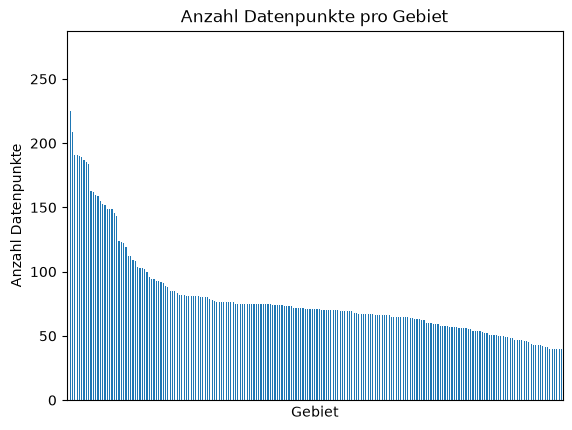

In [14]:
df['Gebiet'].value_counts().plot(kind='bar', 
                                 xticks=[],  # Beschriftung der x-Achse entfernen
                                 xlabel='Gebiet', ylabel='Anzahl Datenpunkte',
                                 title='Anzahl Datenpunkte pro Gebiet');

In [17]:
# Aggregate (Regionen, Einkommensgruppen, Welt) sind keine Länder
aggregate = df[df['Code'].str.startswith('OWID', na=False)]['Gebiet'].unique()
pd.DataFrame(sorted(aggregate), columns=['Gebiet'])

,Gebiet
0,Africa
1,Asia
2,Europe
3,European Union (27)
4,High-income countries
5,Kosovo
6,Low-income countries
7,Lower-middle-income countries
8,North America
9,Oceania


### 2.2 Analyse Codes

In [19]:
print('Anzahl verschiedener Codes:', len(df['Code'].unique()))

Anzahl verschiedener Codes: 213


In [20]:
# Anzahl Datenpunkte pro Code
df['Code'].value_counts()

Code
SWE         274
OWID_WRL    225
FRA         209
AUT         191
BEL         191
           ... 
AIA          40
OWID_KOS     40
MCO          40
NRU          40
SMR          40
Name: count, Length: 213, dtype: int64

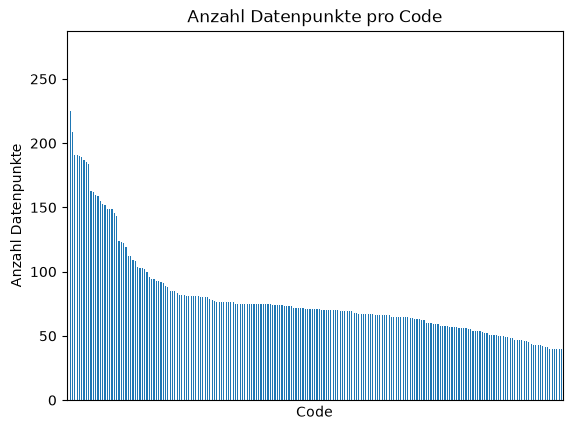

In [21]:
df['Code'].value_counts().plot(kind='bar',xticks=[], ylabel='Anzahl Datenpunkte', title='Anzahl Datenpunkte pro Code');

### 2.3 Analyse Jahr

In [22]:
print('Anzahl verschiedener Jahre: ', len(df['Jahr'].unique()))

Anzahl verschiedener Jahre:  274


In [23]:
# Anzahl Datenpunkte pro Jahr
df['Jahr'].value_counts().sort_index()

Jahr
1751      1
1752      1
1753      1
1754      1
1755      1
       ... 
2020    212
2021    212
2022    212
2023    212
2024    212
Name: count, Length: 274, dtype: int64

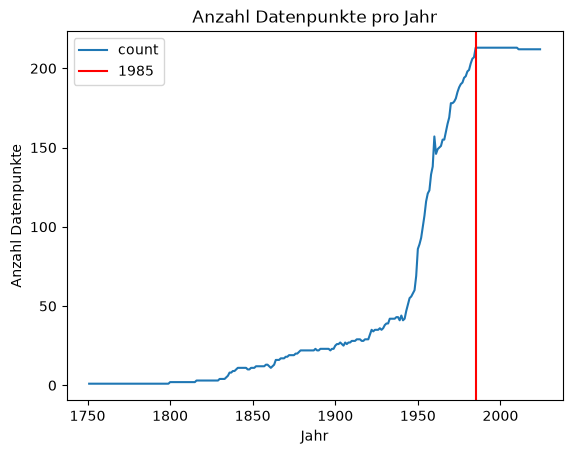

In [26]:
# Jahre mit maximaler Anzahl Datenpunkte (212)
g = df['Jahr'].value_counts().sort_index().plot(xlabel='Jahr', ylabel='Anzahl Datenpunkte',
                                                title='Anzahl Datenpunkte pro Jahr')
g.axvline(x=1985, color='red', label='1985')  # ab hier sind alle Gebiete enthalten
g.legend();

### 2.4 Analyse Kindersterblichkeit

In [27]:
df. describe()

,Jahr,Kindersterblichkeit
count,17066.000000,17066.000000
mean,1975.053557,10.656250
std,41.387351,10.781884
min,1751.000000,0.130000
25%,1960.000000,2.130000
50%,1984.000000,6.490000
75%,2004.000000,16.620000
max,2024.000000,78.090000


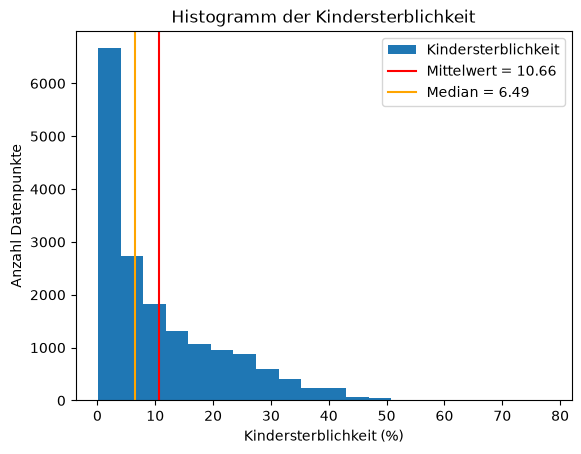

In [28]:
g = df['Kindersterblichkeit'].plot(kind='hist', bins=20, title='Histogramm der Kindersterblichkeit',
                                   xlabel='Kindersterblichkeit (%)', ylabel='Anzahl Datenpunkte')
mean = df['Kindersterblichkeit'].mean()
g.axvline(x=mean, color='red', label=f'Mittelwert = {mean:.2f}')
median = df['Kindersterblichkeit'].median()
g.axvline(x=median, color='orange', label=f'Median = {median:.2f}')
g.legend();

### 2.5 Bereinigung
- Die Daten enthalten neben Ländern auch Aggregate (z. B. *World*, Kontinente und Einkommensgruppen). Diese werden entfernt, da wir die Entwicklung in einzelnen Ländern vergleichen wollen. *Kosovo* hat zwar einen OWID-Code, ist aber ein Land und bleibt deshalb erhalten.
- Es werden nur die Jahre 1990 bis 2024 behalten, da dies der Untersuchungszeitraum unserer Fragestellung ist.


In [29]:
aggregate = [g for g in aggregate if g != 'Kosovo']

df_laender = df[(~df['Gebiet'].isin(aggregate)) & (df['Jahr'].between(1990, 2024))].copy()
df_welt = df[(df['Gebiet'] == 'World') & (df['Jahr'].between(1990, 2024))].copy()

print('Anzahl Länder:', df_laender['Gebiet'].nunique())
print('Jahre:', df_laender['Jahr'].min(), 'bis', df_laender['Jahr'].max())

Anzahl Länder: 201
Jahre: 1990 bis 2024


In [30]:
# Fehlen für 1990 oder 2024 Werte?
anz = df_laender[df_laender['Jahr'].isin([1990, 2024])].groupby('Gebiet')['Jahr'].nunique()
anz[anz < 2]

Gebiet
Taiwan    1
Name: Jahr, dtype: int64